# ImmoAnalyse — exploration et résultats du pipeline

**Objectif.** Présenter les distributions, les anomalies, les taux de conformité et les principaux résultats d'analyse produits par le pipeline (cahier, étape 6).

**Comment lire ce notebook.** Il appelle le pipeline (`executer_pipeline`) puis analyse ses résultats. Il s'exécute **de haut en bas** (`Restart` puis `Run All`) sans erreur et sans rien modifier dans `data/raw/`.

**Rappel important.** Les données sont **synthétiques** (cahier § 5.7) : les chiffres illustrent la méthode, ils ne décrivent pas le marché immobilier réel. Les prix de vente sont des prix **demandés** (annonces), pas des prix de transaction conclue.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est dans notebooks/ : on remonte à la racine du projet pour importer le package src.
sys.path.insert(0, str(Path.cwd().parent))

from src.analysis.qualite import construire_rapport, tableau_regles, valeurs_manquantes, erreurs_conversion
from src.analysis.stats import analyses, retenues
from src.processing.pipeline import executer_pipeline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Date d'exécution FIXÉE : le notebook donne toujours les mêmes résultats (« hier » ou « date future »
# dépendent de cette date). Pour la date du jour, utiliser date.today().
DATE_REF = date(2026, 10, 29)

## 1. Exécution du pipeline

Une seule fonction enchaîne : chargement des 5 sources, normalisation, doublons, rapprochement, règles, décision.

In [2]:
R = executer_pipeline(DATE_REF, simuler_hasard=True)
d = R.donnees
rapport = construire_rapport(R)
print(f"{len(d)} enregistrements reçus  |  fichiers bruts intacts : {R.sources_intactes}")
print(d["statut_final"].value_counts().to_string())

Source agence       :  640 lignes reçues,  680 annoncées


3184 enregistrements reçus  |  fichiers bruts intacts : True
statut_final
conforme                  1393
corrige                    932
conserve_avertissement     658
quarantaine                186
doublon_exact_ecarte        15


## 2. Que reçoit-on ? Volumes et provenance

La **provenance** de chaque enregistrement est conservée (`source`, `id_local`, `ligne_source`) : on peut retrouver n'importe quelle ligne dans son fichier d'origine.

In [3]:
volumes = pd.DataFrame({"annoncées": R.volumes_attendus, "reçues": R.volumes_recus})
volumes["écart"] = volumes["reçues"] - volumes["annoncées"]
volumes

,annoncées,reçues,écart
plateforme,875,875,0
agence,680,640,-40
particuliers,731,731,0
notaires,410,410,0
historique,528,528,0


L'écart de **−40 lignes pour l'agence** vient du fichier (la feuille `Annonces` contient 640 lignes, la fiche en annonce 680). Un pipeline fiable **signale** cet écart au lieu de l'ignorer.

## 3. Décision finale : combien de données sont exploitables ?

Chaque enregistrement reçoit **un seul** statut (priorité : copie exacte > quarantaine > avertissement > corrigé > conforme). Leur somme est exactement le nombre de lignes reçues : aucun enregistrement n'est compté deux fois.

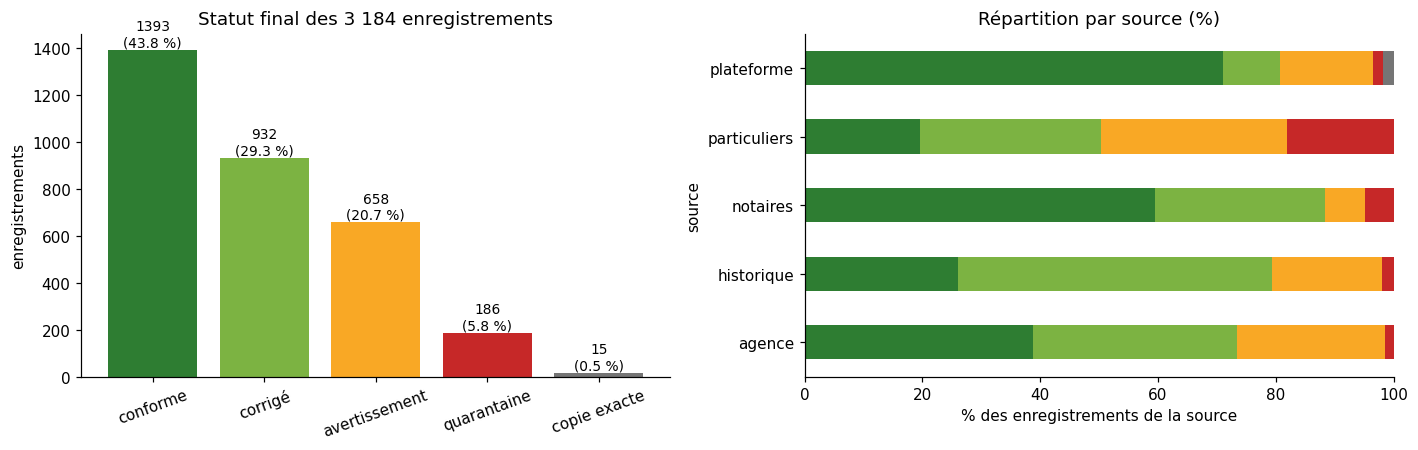

statut_final,conforme,corrige,conserve_avertissement,quarantaine,doublon_exact_ecarte
source,,,,,
agence,248,222,161,9,0
historique,137,282,99,10,0
notaires,244,118,28,20,0
particuliers,143,225,231,132,0
plateforme,621,85,139,15,15


In [4]:
ordre = ["conforme", "corrige", "conserve_avertissement", "quarantaine", "doublon_exact_ecarte"]
couleurs = ["#2e7d32", "#7cb342", "#f9a825", "#c62828", "#757575"]
par_source = d.groupby("source")["statut_final"].value_counts().unstack(1).reindex(columns=ordre).fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
total = d["statut_final"].value_counts().reindex(ordre)
ax[0].bar(range(5), total, color=couleurs)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(["conforme", "corrigé", "avertissement", "quarantaine", "copie exacte"], rotation=20)
for i, v in enumerate(total): ax[0].text(i, v + 15, f"{v}\n({100*v/len(d):.1f} %)", ha="center", fontsize=9)
ax[0].set_title("Statut final des 3 184 enregistrements"); ax[0].set_ylabel("enregistrements")

(par_source.div(par_source.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, color=couleurs, ax=ax[1], legend=False)
ax[1].set_title("Répartition par source (%)"); ax[1].set_xlabel("% des enregistrements de la source")
plt.tight_layout(); plt.show()
par_source.astype(int)

**Lecture.** Les **particuliers** concentrent la quarantaine (prix ou surface absents : la source la plus faible, comme annoncé), alors que les **notaires** et la **plateforme** sont les plus propres. Le taux « exploitable » global est de **93,7 %**, mais seuls **43,8 %** des enregistrements sont *entièrement* conformes (ni corrigés, ni signalés) : la plupart des « corrections » sont des normalisations bénignes (casse, accents, statuts).

## 4. Taux de conformité par règle (avec dénominateur)

`taux = conformes / évaluables × 100`. Les **non évaluables** (ex. « loyer plausible » pour une vente) sont comptés **à part**, jamais comme conformes.

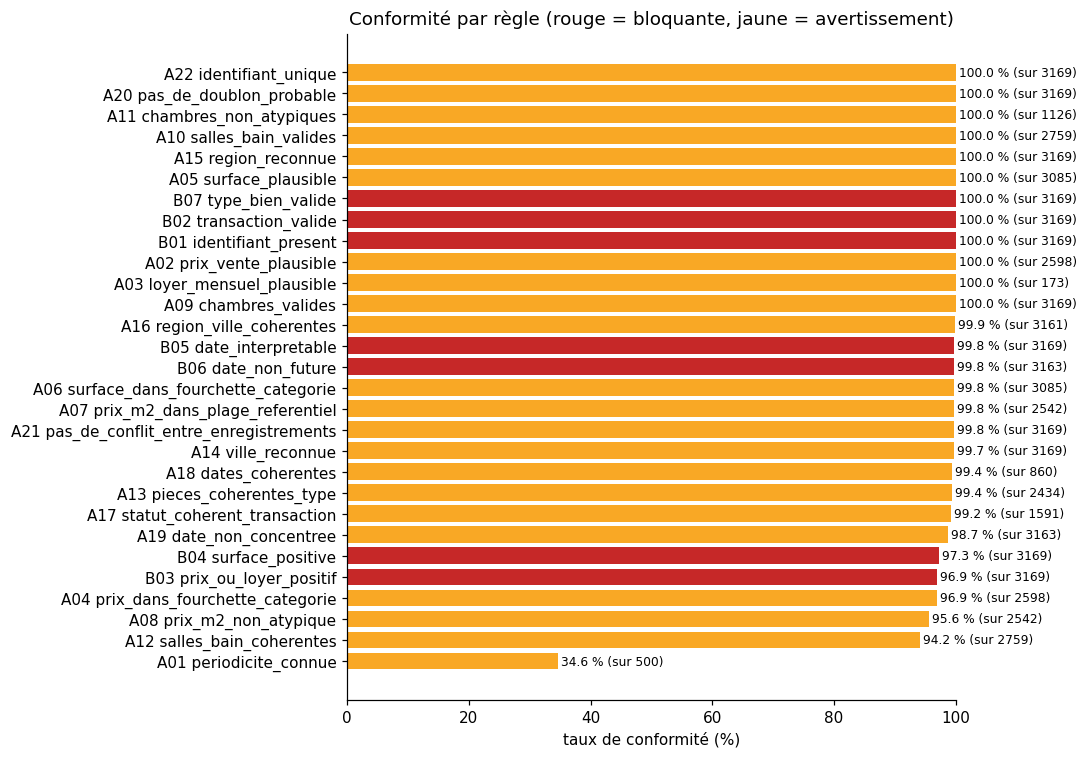

,code,regle,gravite,conformes,non_conformes,non_evaluables,evaluables,taux_conformite_pct
0,B01,identifiant_present,bloquante,3169,0,0,3169,100.0
1,B02,transaction_valide,bloquante,3169,0,0,3169,100.0
2,B03,prix_ou_loyer_positif,bloquante,3072,97,0,3169,96.9
3,B04,surface_positive,bloquante,3085,84,0,3169,97.3
4,B05,date_interpretable,bloquante,3163,6,0,3169,99.8
5,B06,date_non_future,bloquante,3158,5,6,3163,99.8
6,B07,type_bien_valide,bloquante,3169,0,0,3169,100.0
7,A01,periodicite_connue,avertissement,173,327,2669,500,34.6
8,A02,prix_vente_plausible,avertissement,2598,0,571,2598,100.0
9,A03,loyer_mensuel_plausible,avertissement,173,0,2996,173,100.0


In [5]:
regles = tableau_regles(R)
rg = regles.sort_values("taux_conformite_pct")
fig, ax = plt.subplots(figsize=(10, 7))
couleur = rg["gravite"].map({"bloquante": "#c62828", "avertissement": "#f9a825"})
ax.barh(rg["code"] + " " + rg["regle"], rg["taux_conformite_pct"], color=couleur)
ax.set_xlim(0, 100); ax.set_xlabel("taux de conformité (%)")
ax.set_title("Conformité par règle (rouge = bloquante, jaune = avertissement)")
for y, (t, n) in enumerate(zip(rg["taux_conformite_pct"], rg["evaluables"])): ax.text(t + 0.5, y, f"{t:.1f} % (sur {n})", va="center", fontsize=8)
plt.tight_layout(); plt.show()
regles[["code", "regle", "gravite", "conformes", "non_conformes", "non_evaluables", "evaluables", "taux_conformite_pct"]]

**Lecture.** La règle la plus souvent violée est **A01 « périodicité connue »** (34,6 %) : seule la plateforme écrit la périodicité des loyers (`FCFA/mois`) ; pour les 327 autres locations on **ne devine pas** et on signale. Viennent ensuite les salles de bain incohérentes (A12) et le prix au m² atypique (A08).

## 5. Valeurs manquantes et erreurs de conversion

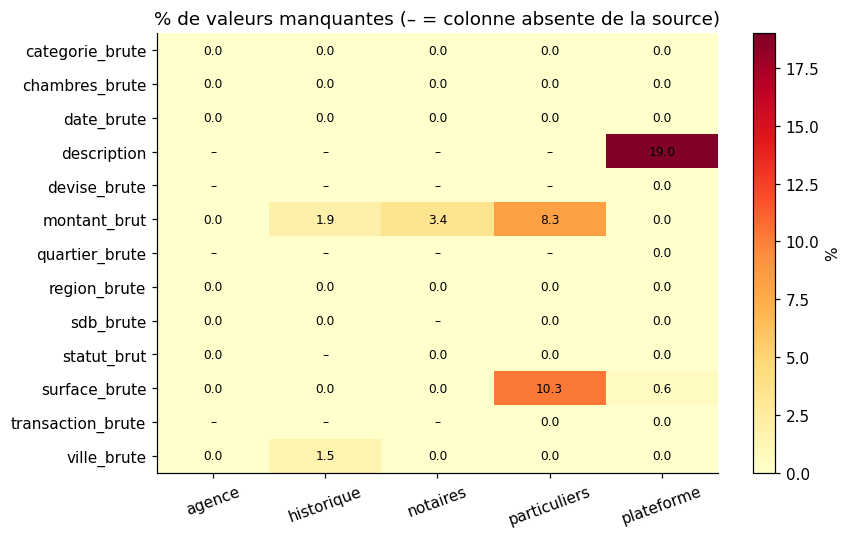

In [6]:
manq = valeurs_manquantes(R)
vm = manq[~manq["colonne_absente"]].pivot(index="colonne", columns="source", values="taux_manquant_pct")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(vm.fillna(0).to_numpy(), cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(vm.shape[1])); ax.set_xticklabels(vm.columns, rotation=20)
ax.set_yticks(range(vm.shape[0])); ax.set_yticklabels(vm.index)
for i in range(vm.shape[0]):
    for j in range(vm.shape[1]):
        v = vm.iloc[i, j]
        ax.text(j, i, "–" if pd.isna(v) else f"{v:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("% de valeurs manquantes (– = colonne absente de la source)"); plt.colorbar(im, label="%")
plt.tight_layout(); plt.show()

In [7]:
conv = erreurs_conversion(R).pivot(index="champ", columns="source", values="erreurs")
conv["total"] = conv.sum(axis=1)
conv[conv["total"] > 0]

source,agence,historique,notaires,particuliers,plateforme,total
champ,,,,,,
date,0,0,6,0,0,6
montant,0,0,0,0,5,5
surface,4,0,0,0,0,4


**Lecture.** Les **particuliers** ont 8,3 % de prix et 10,3 % de surfaces manquants. Les vraies *erreurs de conversion* sont rares (6 dates impossibles chez les notaires, 5 « à négocier », 4 surfaces négatives) parce que la plupart des formats hétérogènes (espaces, « millions », virgule décimale, majuscules) sont **normalisables sans ambiguïté**.

## 6. Formats rencontrés avant normalisation (exemple : le prix)

Le « moule » remplace chaque nombre par `9` et chaque mot par `A` pour voir les familles de formats d'un coup d'œil.

In [8]:
def moule(serie):
    return (serie.astype("string").str.replace(r"\d+", "9", regex=True).str.replace(r"[A-Za-zÀ-ÿ]+", "A", regex=True))

actifs = d[~d["est_copie_exacte"]]
formes = (actifs.assign(forme=moule(actifs["montant_brut"]))
          .groupby("forme", dropna=False)
          .agg(nombre=("forme", "size"), exemple=("montant_brut", "first"), statut=("montant_statut", lambda s: s.mode().iloc[0]))
          .sort_values("nombre", ascending=False))
formes

,nombre,exemple,statut
forme,,,
9,2540,60581000,conforme
9.9,396,320860000.0,conforme
9 9 9,121,438 746 000,corrige
<NA>,85,None,manquant
9.9 A,15,57.62 millions,corrige
A A,7,à négocier,non_numerique
9 A,5,65575000 FCFA,corrige


## 7. Ventes et locations : pourquoi il faut les séparer

Un loyer mensuel de 250 000 FCFA n'est pas comparable à un prix de vente de 250 000 FCFA. Mélanger les deux fausse toutes les statistiques.

In [9]:
a = analyses(R)
a["effet_separation_ventes_locations"]

,ensemble,n,mediane,moyenne
0,tout mélangé (ventes + locations),"2,983.0","59,768,000.0","88,843,072.0"
1,ventes seules (prix demandé),"2,531.0","74,982,000.0","104,634,635.0"
2,locations seules (loyer mensuel),171.0,"315,000.0","395,292.0"


**Lecture.** La médiane « tout mélangé » (≈ 59,8 M FCFA) ne représente **rien** : elle est tirée vers le bas par les loyers. La séparation donne une médiane de vente de ≈ 75 M FCFA et un loyer mensuel médian de ≈ 315 000 FCFA.

## 8. Distributions : prix au m² (ventes) et loyers, par type de bien

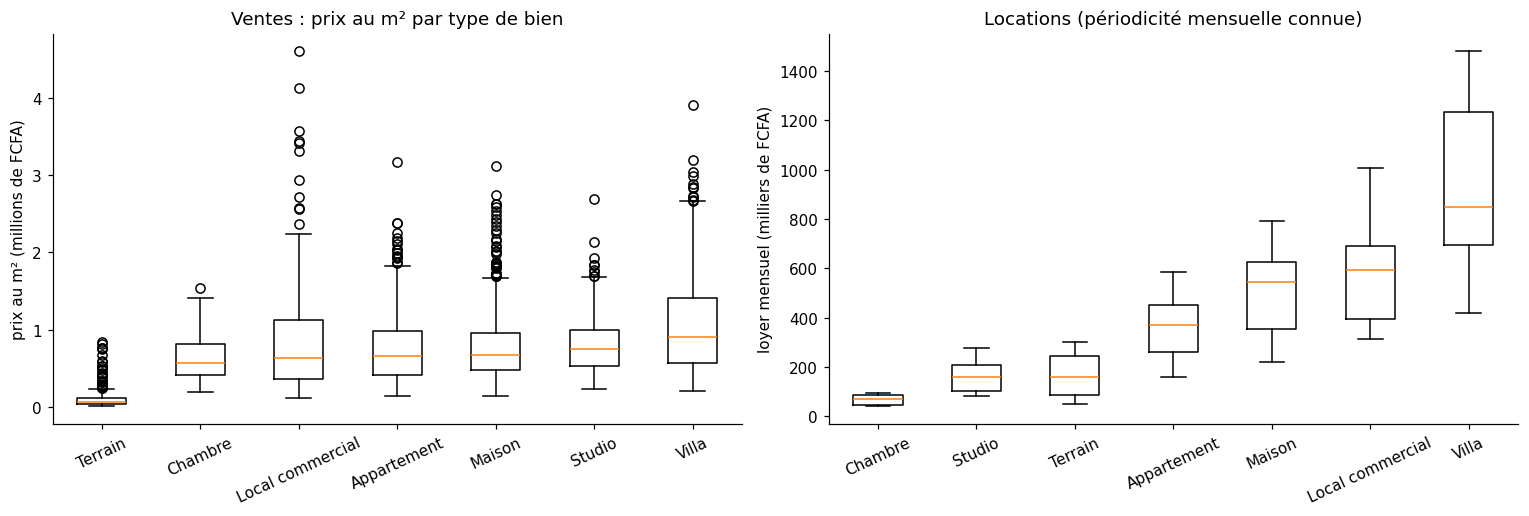

,type_bien,n,moyenne,mediane,ecart_type,min,q1,q3,max
0,Villa,448.0,"1,061,869.4","906,133.3","646,209.2","207,917.9","568,229.0","1,408,773.2","3,908,988.1"
1,Studio,302.0,"814,743.2","748,130.6","388,322.5","236,541.9","529,370.6","995,114.9","2,691,090.9"
2,Maison,535.0,"794,410.6","670,797.6","485,686.4","146,096.0","480,726.6","957,276.1","3,114,201.0"
3,Appartement,590.0,"758,187.0","656,660.7","447,068.9","141,033.9","413,638.7","979,875.9","3,169,958.6"
4,Local commercial,144.0,"921,917.5","625,690.7","853,979.6","111,959.4","366,279.8","1,121,882.0","4,603,187.8"
5,Chambre,157.0,"642,679.3","571,791.9","301,589.3","190,398.6","409,322.0","816,911.8","1,535,663.7"
6,Terrain,355.0,"104,426.2","64,764.9","127,276.7","6,647.9","37,518.0","117,722.4","834,876.5"


In [10]:
r = retenues(R)
ventes = r[(r["type_transaction"] == "vente") & r["prix_m2"].notna()]
ordre_types = ventes.groupby("type_bien")["prix_m2"].median().sort_values().index

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].boxplot([ventes.loc[ventes["type_bien"] == t, "prix_m2"] / 1e6 for t in ordre_types], tick_labels=ordre_types, vert=True, showfliers=True)
ax[0].set_ylabel("prix au m² (millions de FCFA)"); ax[0].set_title("Ventes : prix au m² par type de bien"); ax[0].tick_params(axis="x", rotation=25)

loyers = r[(r["type_transaction"] == "location") & r["loyer_mensuel"].notna()]
ordre_l = loyers.groupby("type_bien")["loyer_mensuel"].median().sort_values().index
ax[1].boxplot([loyers.loc[loyers["type_bien"] == t, "loyer_mensuel"] / 1e3 for t in ordre_l], tick_labels=ordre_l)
ax[1].set_ylabel("loyer mensuel (milliers de FCFA)"); ax[1].set_title("Locations (périodicité mensuelle connue)"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
a["ventes_prix_m2_par_type"]

**Lecture.** Le **terrain** est ≈ 10 fois moins cher au m² que le bâti : on ne calcule **jamais** un prix au m² moyen toutes catégories confondues. À l'intérieur d'une catégorie, la dispersion est forte (de 140 k à plus de 3 M FCFA/m² pour les appartements) : on compare à la **médiane**, moins sensible aux extrêmes que la moyenne.

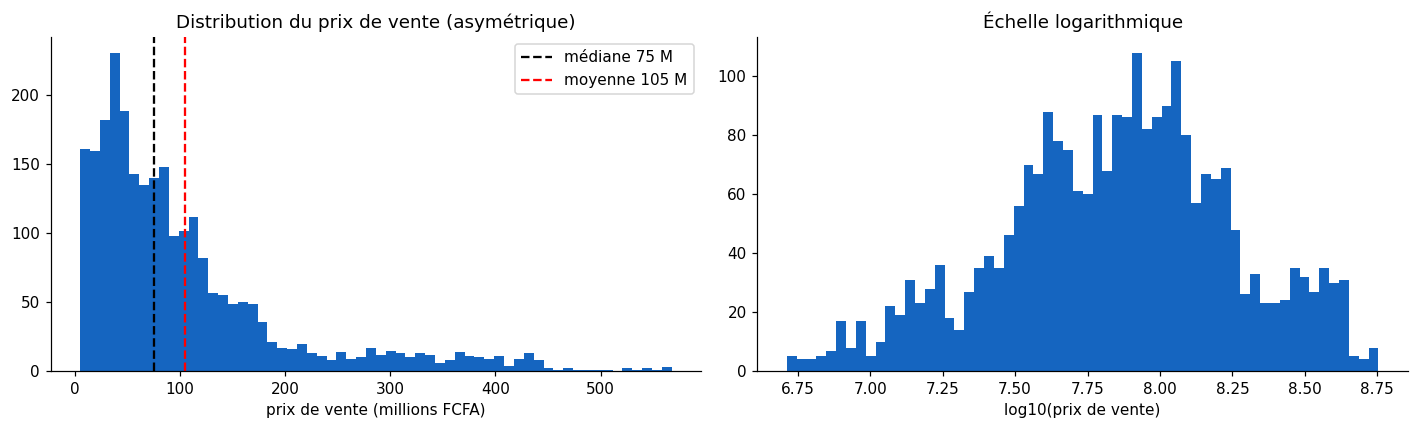

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(ventes["prix_vente"] / 1e6, bins=60, color="#1565c0"); ax[0].set_xlabel("prix de vente (millions FCFA)"); ax[0].set_title("Distribution du prix de vente (asymétrique)")
med, moy = ventes["prix_vente"].median() / 1e6, ventes["prix_vente"].mean() / 1e6
ax[0].axvline(med, color="k", ls="--", label=f"médiane {med:.0f} M"); ax[0].axvline(moy, color="r", ls="--", label=f"moyenne {moy:.0f} M"); ax[0].legend()
ax[1].hist(np.log10(ventes["prix_vente"]), bins=60, color="#1565c0"); ax[1].set_xlabel("log10(prix de vente)"); ax[1].set_title("Échelle logarithmique")
plt.tight_layout(); plt.show()

**Lecture.** La distribution des prix est **asymétrique à droite** : la moyenne dépasse la médiane. C'est pourquoi la médiane est le meilleur résumé.

## 9. Anomalies atypiques : erreur ou valeur légitime ?

Les avertissements sont des **signaux**, pas des verdicts. Exemple : un bien extrême en prix ou en surface n'est suspect que si son **prix au m²** l'est aussi.

In [12]:
cas = ["plateforme:PLT-00663", "plateforme:PLT-00193", "plateforme:PLT-00362", "plateforme:PLT-00480"]
ventes_all = r[(r["type_transaction"] == "vente") & r["prix_m2"].notna()].copy()
ventes_all["rang_percentile_dans_categorie"] = ventes_all.groupby("type_bien")["prix_m2"].rank(pct=True) * 100
ventes_all[ventes_all["id_bien"].isin(cas)][["id_bien", "type_bien", "prix_vente", "surface_m2", "prix_m2", "rang_percentile_dans_categorie"]].round(1)

,id_bien,type_bien,prix_vente,surface_m2,prix_m2,rang_percentile_dans_categorie
192,plateforme:PLT-00193,Villa,"450,000,000.0","1,250.0","360,000.0",8.9
361,plateforme:PLT-00362,Appartement,"17,785,000.0",47.6,"373,634.5",20.0
479,plateforme:PLT-00480,Appartement,"116,227,000.0",219.9,"528,544.8",35.8
662,plateforme:PLT-00663,Appartement,"340,802,000.0",389.7,"874,524.0",69.0


**Lecture.** Ces quatre annonces sortent des fourchettes de prix ou de surface de leur catégorie, mais leur prix au m² est **ordinaire** (rang de 9 % à 69 % dans leur catégorie, sur l'ensemble des sources) : prix et surface vont ensemble, ce ne sont pas des erreurs de saisie. On les **conserve avec un avertissement**.

### Le lot suspect de la plateforme

Quarante annonces (PLT-02602 à PLT-02680) partagent la **même date**, le même statut « En vente » et **0 chambre / 0 salle de bain**, y compris des villas : signature d'un import en masse avec valeurs par défaut.

In [13]:
lot = d[d["id_local"].str.extract(r"(\d+)$")[0].astype(float).between(2600, 2700) & (d["source"] == "plateforme")]
print(len(lot), "annonces |", lot["date_collecte"].unique(), "|", lot["statut_source"].unique())
print(lot["type_bien"].value_counts().to_dict(), "| chambres :", lot["chambres"].unique().tolist())

40 annonces | <StringArray>
['2024-03-01']
Length: 1, dtype: str | ['En vente']
{'Maison': 8, 'Terrain': 8, 'Studio': 8, 'Chambre': 6, 'Local commercial': 4, 'Villa': 4, 'Appartement': 2} | chambres : [0]


## 10. Doublons exacts, doublons probables et conflits

- **Doublon exact** : tous les champs identiques → copie écartée (15, toutes dans la plateforme, en fin de fichier).
- **Doublon probable / conflit** : on rapproche sur des **attributs métier** (ville, type, transaction, puis un score de surface, prix, pièces, date), jamais sur l'identifiant. Rien n'est fusionné.

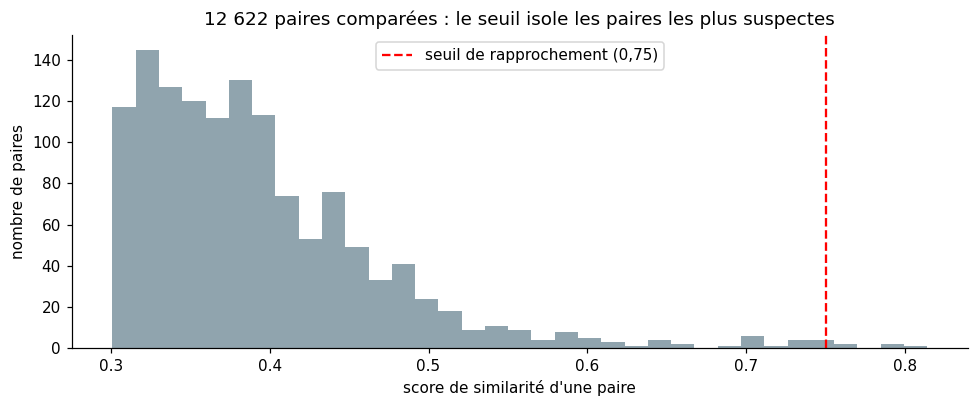

,id_a,id_b,ville,type_bien,score,type_lien,champs_en_conflit
0,particuliers:PRT-01461,particuliers:PRT-02191,Gossas,Studio,0.8,conflit,prix
1,plateforme:PLT-00314,plateforme:PLT-00587,Podor,Appartement,0.8,conflit,salles_bain
2,agence:AGT-01179,historique:HIS-0071,Vélingara,Appartement,0.8,conflit,"chambres,salles_bain"


In [14]:
p = R.paires
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(p.loc[p["score"] > 0.3, "score"], bins=35, color="#90a4ae")
ax.axvline(0.75, color="r", ls="--", label="seuil de rapprochement (0,75)")
ax.set_xlabel("score de similarité d'une paire"); ax.set_ylabel("nombre de paires")
ax.set_title(f"{len(p):,} paires comparées : le seuil isole les paires les plus suspectes".replace(",", " ")); ax.legend()
plt.tight_layout(); plt.show()
R.rapprochements[["id_a", "id_b", "ville", "type_bien", "score", "type_lien", "champs_en_conflit"]]

In [15]:
print("Paires retenues :", len(R.rapprochements))
print("Faux doublons attendus par pur hasard (test par permutation) :", R.coincidences)

Paires retenues : 3
Faux doublons attendus par pur hasard (test par permutation) : {'moyenne': 4.9, 'min': 3, 'max': 8, 'tirages': 10}


**Lecture prudente.** Le hasard produirait en moyenne **≈ 5 « paires retenues »** avec ces critères, contre 3 observées : ces paires sont des **signaux à vérifier à la main**, pas des preuves. Une seule porte une signature nette de variante volontaire : `PRT-01461` / `PRT-02191` (même surface 50,0 m², même nombre de pièces, prix exactement ×0,95 : 18 152 000 × 0,95 = 17 244 400). Les conflits sont **signalés, pas résolus arbitrairement**.

## 11. Résultats d'analyse sur les données retenues

In [16]:
a["ventes_prix_m2_par_region"]

,region,n,moyenne,mediane,ecart_type,min,q1,q3,max
0,Dakar,207.0,"888,175.1","772,681.8","674,046.4","9,864.8","411,639.4","1,211,032.7","3,908,988.1"
1,Saint-Louis,162.0,"789,949.2","682,440.9","620,447.4","7,094.1","395,038.9","946,739.1","3,436,736.0"
2,Kaffrine,178.0,"685,246.9","659,039.0","457,357.7","17,121.9","358,724.3","904,463.7","3,197,083.0"
3,Thiès,177.0,"760,524.5","652,714.4","607,685.5","13,734.8","346,583.8","1,008,945.1","4,603,187.8"
4,Kolda,181.0,"685,125.6","650,046.7","430,400.3","12,613.4","365,855.2","942,136.7","1,818,693.7"
5,Matam,194.0,"737,904.5","625,524.0","548,230.3","16,000.6","343,435.2","1,051,690.3","2,885,783.8"
6,Kédougou,164.0,"754,157.9","624,214.1","602,456.0","17,691.8","338,495.7","992,416.4","3,038,844.5"
7,Diourbel,198.0,"772,834.4","618,456.9","645,700.2","6,647.9","359,767.1","1,080,126.2","4,135,138.2"
8,Louga,187.0,"734,721.3","612,212.1","538,498.6","11,580.3","364,295.0","974,405.9","3,413,284.8"
9,Sédhiou,194.0,"738,172.1","598,684.1","563,320.8","14,608.1","378,326.2","895,668.7","2,664,918.8"


In [17]:
a["locations_loyer_mensuel_par_type"]

,type_bien,n,moyenne,mediane,ecart_type,min,q1,q3,max
0,Villa,21.0,"930,238.1","850,000.0","316,439.1","420,000.0","695,000.0","1,235,000.0","1,480,000.0"
1,Local commercial,6.0,"592,500.0","592,500.0","256,139.6","315,000.0","392,500.0","691,250.0","1,005,000.0"
2,Maison,31.0,"515,000.0","545,000.0","173,243.6","220,000.0","355,000.0","627,500.0","790,000.0"
3,Appartement,53.0,"367,264.2","370,000.0","118,238.5","160,000.0","260,000.0","450,000.0","585,000.0"
4,Studio,23.0,"159,347.8","160,000.0","59,109.0","80,000.0","102,500.0","207,500.0","275,000.0"
5,Terrain,29.0,"167,758.6","160,000.0","83,778.9","50,000.0","85,000.0","245,000.0","300,000.0"
6,Chambre,8.0,"68,125.0","70,000.0","23,289.7","40,000.0","45,000.0","87,500.0","95,000.0"


## 12. Conclusions et limites

- **93,7 %** des enregistrements sont exploitables, **5,8 %** sont en quarantaine (chacun avec son motif), **0,5 %** sont des copies exactes.
- Les **particuliers** sont la source la moins fiable (prix et surface manquants) ; les **notaires** et la **plateforme** la plus fiable.
- Les formats hétérogènes (espaces, « millions », virgule décimale, majuscules, dates JJ/MM) sont normalisés **sans deviner** ; ce qui reste ambigu est signalé (périodicité des loyers) ou rejeté (dates impossibles).
- **Limites** : données synthétiques ; seuils = hypothèses pédagogiques ; prix de vente = prix demandés ; rapprochement entre sources peu discriminant (les paires retenues sont indistinguables du hasard) ; 40 annonces de l'agence annoncées mais absentes du fichier.